# Modelo: arquitectura, entrenamiento y evaluación

Proyecto final — Tecnicatura en Ciencias de Datos. Bimestre 1 (local).

**Objetivo.** Mostrar el modelo entrenado y sus resultados. El entrenamiento no se ejecuta
en este notebook: se corrió con `python -m src.models.train`, porque SageMaker requiere un
script. Acá se carga el modelo ya guardado y se reutilizan las funciones de `src/`, sin
duplicar código.

| Sección | Qué muestra |
|---|---|
| 1. El modelo | Qué partes vienen preentrenadas, cuál se entrenó y cómo recorre una imagen |
| 2. El entrenamiento | Cómo evolucionó época por época y por qué se conservó la época 15 |

---
## 0. Setup

Mismo setup que los notebooks anteriores. Requiere `models/model.pth`, que se genera con
`train.py` y no se versiona.

`evaluate.py` configura matplotlib para ejecutarse sin pantalla, como en SageMaker. La línea
`%matplotlib inline`, posterior a los imports, vuelve a habilitar los gráficos en el
notebook.

In [1]:
import json
from pathlib import Path
import sys

REPO_DIR = str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from dotenv import load_dotenv
from PIL import Image

from src.data import eda
from src.data.augmentation import get_eval_pipeline
from src.data.dataset import CLASES
from src.data.preprocessing import split_dataset
from src.models.architecture import build_model
from src.models.evaluate import cargar_modelo

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
MODEL_DIR = Path(REPO_DIR) / "models"

In [2]:
load_dotenv(Path(REPO_DIR) / ".env")
import kagglehub

ruta_dataset = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
df_train, df_val, df_test = split_dataset(eda.listar_imagenes(ruta_dataset))
print(f"train: {len(df_train):,} | val: {len(df_val):,} | test: {len(df_test):,}")

train: 4,909 | val: 701 | test: 1,403


---
## 1. El modelo

EfficientNet-B0 fue entrenada previamente con más de un millón de fotografías generales
(ImageNet). Ese entrenamiento le permite reconocer patrones visuales: bordes, texturas y
formas. El proyecto reutiliza ese conocimiento y solo entrena la última capa, que decide a
cuál de las 4 clases corresponde una imagen (*transfer learning* con el backbone congelado).

### 1.1 Qué se entrenó y qué no

Un **parámetro** es un número interno que el modelo ajusta al aprender. En PyTorch, el
atributo `requires_grad` indica si ese número puede modificarse durante el
entrenamiento.

In [3]:
model = cargar_modelo(MODEL_DIR)
model.eval()

partes = {
    "features (backbone)": model.features,
    "avgpool": model.avgpool,
    "classifier (capa final)": model.classifier,
}
tabla = pd.DataFrame(
    {
        nombre: {
            "parámetros": sum(p.numel() for p in parte.parameters()),
            "entrenables": sum(p.numel() for p in parte.parameters() if p.requires_grad),
        }
        for nombre, parte in partes.items()
    }
).T
tabla.loc["TOTAL"] = tabla.sum()
print(f"Entrenables: {tabla.loc['TOTAL', 'entrenables'] / tabla.loc['TOTAL', 'parámetros']:.2%} del total")
tabla

Entrenables: 0.13% del total


,parámetros,entrenables
features (backbone),4007548,0
avgpool,0,0
classifier (capa final),5124,5124
TOTAL,4012672,5124


**Lectura.** Solo se entrenan 5.124 de los 4.012.672 parámetros. El número surge de la capa
final: recibe 1.280 valores y produce 4 puntajes, es decir 1.280 × 4 pesos más 4 términos
independientes (uno por clase). Por eso el entrenamiento es viable en CPU.

### 1.2 Verificación: el backbone no cambió

Que el backbone esté configurado como congelado no demuestra que haya quedado intacto. Sus
capas BatchNorm también guardan estadísticas que pueden actualizarse aunque los pesos estén
fijos; `train.modo_entrenamiento()` lo evita. Para comprobarlo, comparo cada valor del
backbone entrenado con el original de ImageNet.

In [4]:
original = build_model(num_classes=len(CLASES), pretrained=True).features.state_dict()
entrenado = model.features.state_dict()

distintos = [nombre for nombre in original if not torch.equal(original[nombre], entrenado[nombre])]
print(f"Componentes del backbone comparados: {len(original)}")
print(f"Componentes que cambiaron: {len(distintos)}")

Componentes del backbone comparados: 358


Componentes que cambiaron: 0


### 1.3 El recorrido de una imagen

Sigo una imagen de validación a través del modelo. Cada paso la resume: de una grilla de
píxeles a 4 puntajes, uno por clase. El modelo devuelve puntajes sin escala (*logits*); la
función *softmax* los convierte en probabilidades que suman 1.

In [5]:
ejemplo = df_val[df_val["clase"] == "glioma"].iloc[0]
imagen = Image.open(ejemplo["path"]).convert("RGB")
entrada = get_eval_pipeline()(imagen).unsqueeze(0)  # agrega la dimensión del batch: (1, 3, 224, 224)

with torch.no_grad():
    mapas = model.features(entrada)
    resumen = torch.flatten(model.avgpool(mapas), 1)
    logits = model.classifier(resumen)
    proba = torch.softmax(logits, dim=1)
    # El recorrido paso a paso tiene que dar lo mismo que llamar al modelo completo.
    assert torch.allclose(logits, model(entrada))

pd.DataFrame(
    [
        ("Imagen de entrada", tuple(entrada.shape), "1 imagen, 3 canales, 224 × 224 píxeles"),
        ("Después de features", tuple(mapas.shape), "1.280 mapas de patrones de 7 × 7"),
        ("Después de avgpool", tuple(resumen.shape), "Cada mapa resumido en un número"),
        ("Después de classifier", tuple(logits.shape), "Un puntaje por clase"),
    ],
    columns=["Paso", "Forma", "Significado"],
)

,Paso,Forma,Significado
0,Imagen de entrada,"(1, 3, 224, 224)","1 imagen, 3 canales, 224 × 224 píxeles"
1,Después de features,"(1, 1280, 7, 7)",1.280 mapas de patrones de 7 × 7
2,Después de avgpool,"(1, 1280)",Cada mapa resumido en un número
3,Después de classifier,"(1, 4)",Un puntaje por clase


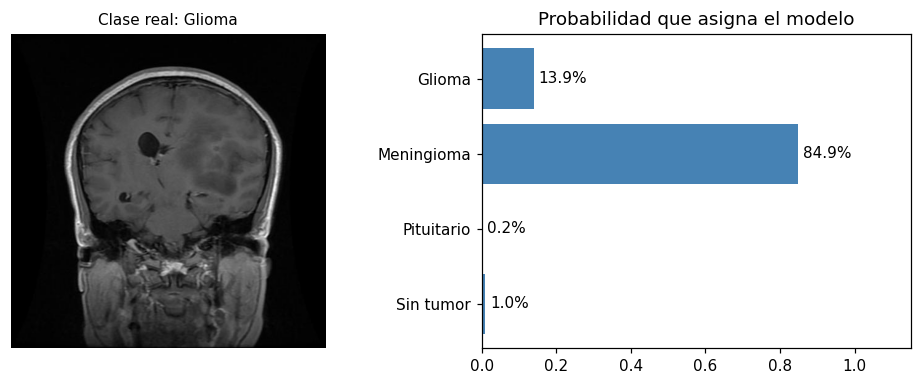

In [6]:
fig, (ax_img, ax_proba) = plt.subplots(1, 2, figsize=(9, 3.6))
ax_img.imshow(imagen)
ax_img.set_title(f"Clase real: {eda.ETIQUETAS[ejemplo['clase']]}", fontsize=10)
ax_img.axis("off")

barras = ax_proba.barh([eda.ETIQUETAS[c] for c in CLASES], proba[0].tolist(), color="steelblue")
ax_proba.bar_label(barras, labels=[f"{p:.1%}" for p in proba[0].tolist()], padding=3)
ax_proba.invert_yaxis()
ax_proba.set(title="Probabilidad que asigna el modelo", xlim=(0, 1.15))
plt.tight_layout()
plt.show()

**Lectura.** La clase con mayor probabilidad es la predicción. En este caso el modelo se
equivoca: es un glioma y le asigna 84,9% a meningioma, la confusión más frecuente del
proyecto (ver `docs/model_card.md`). Detecta que hay un tumor (1,0% para "Sin tumor"), pero
no acierta el tipo. También muestra que una probabilidad alta no garantiza una predicción
correcta.

Es un único caso, elegido por su posición en la lista y no por su resultado: ilustra el
mecanismo y no mide el desempeño del modelo.

---
## 2. El entrenamiento

Una **época** es una pasada completa por todas las imágenes de entrenamiento. Al final de
cada una, `train.py` mide el modelo sobre validación (imágenes que no usa para aprender) y
guarda el resultado en `historial.json`. Esta sección lee ese archivo; no vuelve a entrenar.

El entrenamiento se detiene cuando el **recall promedio de validación** no mejora durante 5
épocas seguidas (*early stopping*), y conserva el modelo de la mejor época, no el último.

In [7]:
historial = json.loads((MODEL_DIR / "historial.json").read_text(encoding="utf-8"))

curvas = pd.DataFrame(
    [
        {
            "época": h["epoca"],
            "loss train": h["loss_train"],
            "loss val": h["val"]["loss"],
            "recall val": h["val"]["recall_macro"],
            "glioma": h["val"]["recall_por_clase"]["glioma"],
            "meningioma": h["val"]["recall_por_clase"]["meningioma"],
            "tumores como sanos": h["val"]["tumores_como_sanos"],
        }
        for h in historial
    ]
).set_index("época")

mejor = curvas["recall val"].idxmax()
print(f"Épocas: {len(curvas)} | mejor: {mejor} | duración: {sum(h['segundos'] for h in historial) / 60:.0f} minutos")
curvas.round(3)

Épocas: 20 | mejor: 15 | duración: 52 minutos


,loss train,loss val,recall val,glioma,meningioma,tumores como sanos
época,,,,,,
1,0.640,0.399,0.870,0.844,0.708,7
2,0.416,0.331,0.893,0.860,0.758,6
3,0.371,0.301,0.892,0.866,0.742,6
4,0.347,0.279,0.906,0.849,0.815,3
5,0.334,0.268,0.914,0.832,0.854,3
6,0.317,0.253,0.915,0.866,0.837,3
7,0.302,0.251,0.916,0.804,0.910,3
8,0.293,0.246,0.912,0.799,0.871,6
9,0.283,0.243,0.916,0.860,0.837,6


### 2.1 ¿El modelo aprendió o memorizó?

La **loss** mide cuánto se equivoca el modelo: cuanto más baja, mejor. Si memorizara las
imágenes de entrenamiento (*sobreajuste*), la loss de train seguiría bajando mientras la de
validación empieza a subir.

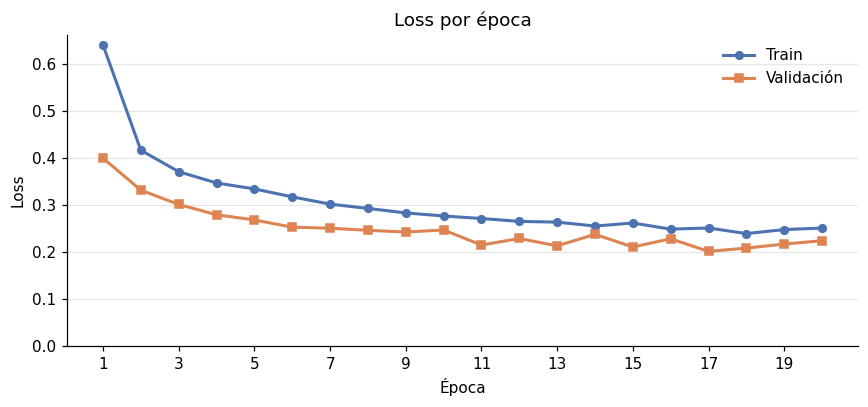

In [8]:
AZUL, NARANJA = "#4C72B0", "#DD8452"


def estilo(ax, titulo, eje_y):
    ax.set(title=titulo, xlabel="Época", ylabel=eje_y, xticks=range(1, len(curvas) + 1, 2))
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curvas["loss train"], color=AZUL, linewidth=2, marker="o", markersize=5, label="Train")
ax.plot(curvas["loss val"], color=NARANJA, linewidth=2, marker="s", markersize=5, label="Validación")
estilo(ax, "Loss por época", "Loss")
ax.set_ylim(0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Lectura.** Las dos curvas bajan y terminan cerca una de la otra: no hay señales claras de
sobreajuste. Entre las épocas 17 y 20 la loss de validación sube levemente (de 0,201 a 0,224),
un movimiento similar a las oscilaciones de las épocas anteriores. Con solo 5.124 parámetros entrenables, el modelo tiene poca
capacidad para memorizar.

La loss de validación queda por debajo de la de train, al revés de lo habitual. Es esperable:
en train las imágenes llevan augmentation y la capa final usa Dropout, dos dificultades que no
se aplican en validación.

### 2.2 ¿Por qué la época 15?

Es la de mayor recall promedio en validación. Las 5 siguientes no la superaron y el
entrenamiento se cortó en la 20.

La validación tiene unas 175 imágenes por clase, por lo que cada valor tiene un margen de
error. Lo estimo para saber si la diferencia entre épocas es relevante.

Recall de la época 15: 92.8% (margen aproximado: ±1.8%)
Épocas 5 a 20 dentro de ese margen: 15 de 16
Rango desde la época 5: 90.7% a 92.8%
Época con menor loss de validación: 17


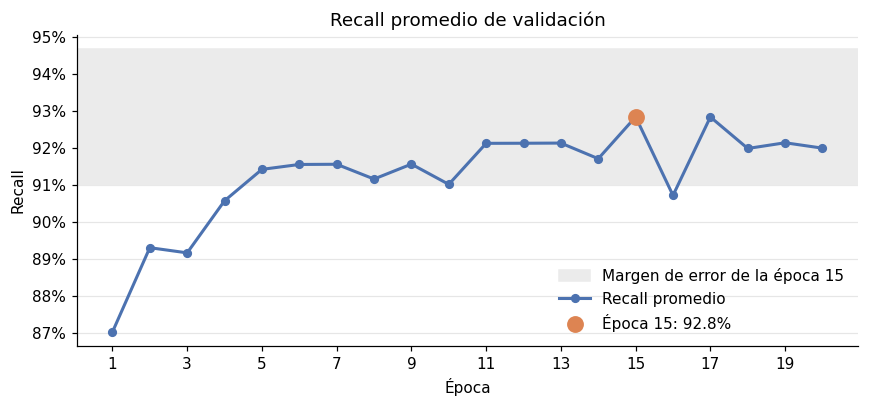

In [9]:
n_val = df_val["clase"].value_counts()
recall_mejor = historial[mejor - 1]["val"]["recall_por_clase"]
# Margen aproximado (95%) del promedio de los 4 recalls, tratados como proporciones independientes.
margen = 1.96 * np.sqrt(sum(recall_mejor[c] * (1 - recall_mejor[c]) / n_val[c] for c in CLASES)) / len(CLASES)
valor = curvas.loc[mejor, "recall val"]
print(f"Recall de la época {mejor}: {valor:.1%} (margen aproximado: ±{margen:.1%})")
dentro = curvas.loc[5:, "recall val"] >= valor - margen
print(f"Épocas 5 a {len(curvas)} dentro de ese margen: {dentro.sum()} de {len(dentro)}")
print(f"Rango desde la época 5: {curvas.loc[5:, 'recall val'].min():.1%} a {curvas.loc[5:, 'recall val'].max():.1%}")
print(f"Época con menor loss de validación: {curvas['loss val'].idxmin()}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.axhspan(valor - margen, valor + margen, color="0.92", label="Margen de error de la época 15")
ax.plot(curvas["recall val"], color=AZUL, linewidth=2, marker="o", markersize=5, label="Recall promedio")
ax.plot(mejor, valor, marker="o", markersize=10, color=NARANJA, linestyle="none", label=f"Época {mejor}: {valor:.1%}")
estilo(ax, "Recall promedio de validación", "Recall")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Lectura.** La época 15 es la mejor, pero por poco: 15 de las 16 épocas posteriores a la 4
quedan dentro de su margen de error (±1,8 puntos), y la 17 tiene un recall casi idéntico y una
loss de validación menor. La única que queda afuera es la 16 (90,7%).

La conclusión es que el modelo llega a una meseta alrededor del 92%, y no que la época 15 sea
significativamente superior. El margen es aproximado: supone que los recalls por clase son
independientes y no considera que todas las épocas se miden sobre las mismas imágenes.

### 2.3 Glioma y meningioma compiten entre sí

El promedio es estable, pero oculta un movimiento entre dos clases.

Cambios de época en sentidos opuestos: 15 de 19
Correlación entre ambos recalls: -0.67


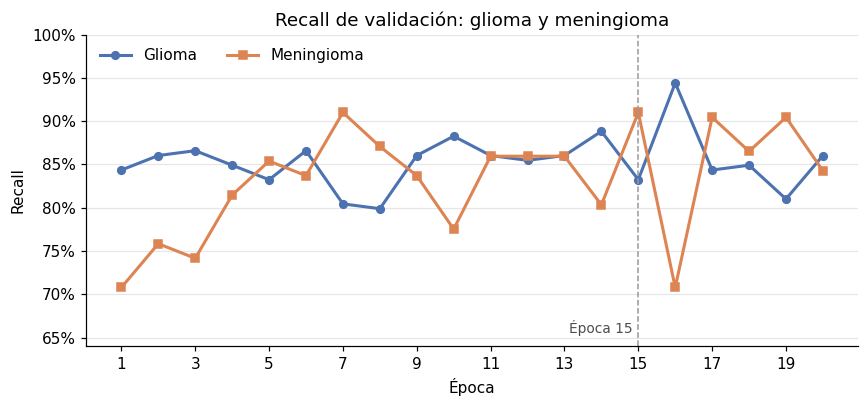

In [10]:
cambio_glioma, cambio_meningioma = np.diff(curvas["glioma"]), np.diff(curvas["meningioma"])
opuestos = (cambio_glioma * cambio_meningioma < 0).sum()
print(f"Cambios de época en sentidos opuestos: {opuestos} de {len(cambio_glioma)}")
print(f"Correlación entre ambos recalls: {np.corrcoef(curvas['glioma'], curvas['meningioma'])[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curvas["glioma"], color=AZUL, linewidth=2, marker="o", markersize=5, label="Glioma")
ax.plot(curvas["meningioma"], color=NARANJA, linewidth=2, marker="s", markersize=5, label="Meningioma")
ax.axvline(mejor, color="0.6", linewidth=1, linestyle="--")
ax.annotate(f"Época {mejor}", (mejor, 0.655), xytext=(-4, 0), textcoords="offset points", ha="right", fontsize=9, color="0.3")
estilo(ax, "Recall de validación: glioma y meningioma", "Recall")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_ylim(0.64, 1)
ax.legend(frameon=False, loc="upper left", ncols=2)
plt.tight_layout()
plt.show()

**Lectura.** En 15 de 19 cambios de época, cuando mejora una clase empeora la otra. El caso más
claro es la época 16: glioma sube a 94,4% y meningioma cae a 70,8%. Es compatible con que el
modelo mueva el límite entre dos clases que le resultan parecidas: al favorecer a una,
perjudica a la otra. Esta sección solo muestra la oscilación; la confusión entre ambas se
comprueba con la matriz de test (ver `docs/model_card.md`).

También muestra una consecuencia de elegir por el promedio: en la época 15 meningioma tiene
91,0% y glioma 83,2%. Otra época con un promedio similar habría repartido los errores de otra
manera.